# **Team Details**

In [82]:
"""
TEAM Number : 20
TEAM Members :
1. Arpit Puri, ID:2023A7PS0132H
2. Shrey Katiyar, ID:2023A2PS0908H
3. Kartikeya Srivastava, ID:2023A3PS0385H
4. Siddharth Malawat, ID:2023A3PS1068H
"""

'\nTEAM Number : 20\nTEAM Members :\n1. Arpit Puri, ID:2023A7PS0132H\n2. Shrey Katiyar, ID:2023A2PS0908H\n3. Kartikeya Srivastava, ID:2023A3PS0385H\n4. Siddharth Malawat, ID:2023A3PS1068H\n'

# **Intalling Dependencies**

In [83]:
# Necessary dependencies
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install scikit-learn

# **Importing Libraries**

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **Data Understanding and Preprocessing**


1. Load and inspect the dataset structure (size, variables, data types).
2. Identify numerical and categorical features.
3. Define a dependent feature as the regression target.
4. Justify the selection of numerical input features.






In [85]:

df = pd.read_csv('Dataset.csv')
print("First 5 rows of the DataFrame:")
print(df.head())

print("\nShape of the DataFrame (rows, columns):")
print(df.shape)

print("\nDataFrame Info:")
df.info()

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_info = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})
print("\n")
print("Missing Values in Each Column:")
print(missing_info[missing_info['Missing Values'] > 0])

df['Intervention_Type'] = df['Intervention_Type'].fillna('No Intervention')
print("\nMissing values in 'Intervention_Type' after imputation:")
print(df['Intervention_Type'].isnull().sum())

print("\nTotal missing values in the DataFrame after handling:")
print(df.isnull().sum().sum())


First 5 rows of the DataFrame:
  Crop_Type Fertilizer_Type  Nitrogen_kg_ha Irrigation_Method  \
0   Soybean       Synthetic      232.998485         Sprinkler   
1   Soybean       Synthetic      141.237938         Sprinkler   
2   Soybean       Synthetic      161.065486         Sprinkler   
3   Soybean       Synthetic      160.219869         Sprinkler   
4      Rice           Mixed      201.886213             Flood   

   Irrigation_Water_mm  Avg_Temperature_C  Rainfall_mm  Humidity_%  \
0           798.658484          13.900466   487.193424   42.904181   
1           713.986285          15.732909   487.193424   42.904181   
2           642.881174          15.332411   487.193424   42.904181   
3           617.580538          15.356536   487.193424   42.904181   
4           370.524124          11.626290  1438.662645   88.281602   

    CO2_kg_ha  CH4_kg_ha  N2O_kg_ha  Total_GHG_kgCO2e   Scenario_Type  \
0  660.659923   3.832290   2.935502       1631.246917        Baseline   
1  588.4930

**Numerical Features:**

1.   Nitrogen_kg_ha
2.   Irrigation_Water_mm
3. Avg_Temperature_C
4. Rainfall_mm
5. Humidity_%
6. CO2_kg_ha
7. CH4_kg_ha
8. N2O_kg_ha
9. Total_GHG_kgCO2e

**Categorical Features:**

1. Crop_Type
2. Fertilizer_Type
3. Irrigation_Method
4. Scenario_Type
5. Intervention_Type

**Dependent Feature:** Total_GHG_kgCO2e

**Numerical Input Features:**

1. Nitrogen_kg_ha: Directly increases soil N₂O emissions due to fertilizer microbial activity.
2. Irrigation_Water_mm: Influences soil moisture levels, affecting methane and nitrous oxide emissions.
3. Avg_Temperature_C: Higher temperatures accelerate biochemical reactions that increase GHG emissions.
4. Rainfall_mm: Affects soil saturation and denitrification, impacting emission levels.
5. Humidity_%: Impacts soil moisture retention and indirectly influences greenhouse gas production.

**Justification for exclusion:**

Features excluded: CO2_kg_ha, CH4_kg_ha, N2O_kg_ha

Including them would:

* Cause leakage   
* Make the regression meaningless  
* Artificially inflate model accuracy
* No real predictive insight is gained.


**Approximate formula used:**

*Total GHG=$CO_2$​+($CH_4​$×28)+($N_2​$O×265)*

Source: [2006 IPCC Guidelines for National Greenhouse Gas Inventories](https://www.iges.or.jp/en/pub/2006-ipcc-guidelines-national-green-gas/en?utm_source=chatgpt.com)





# **Exploratory Data Analysis (EDA)**
1. Compute descriptive statistics for numerical variables.
2. Visualize feature distributions using histograms and boxplots.
3. Analyze relationships between inputs and the target using scatter plots.
4. Compute and visualize a correlation matrix.
5. Include additional plots wherever useful.
6. Summarize the key observations and report at least three data-driven insights.

       Nitrogen_kg_ha  Irrigation_Water_mm  Avg_Temperature_C   Rainfall_mm  \
count    40000.000000         40000.000000       40000.000000  40000.000000   
mean       142.765778           593.846482          23.444599    896.385823   
std         63.900585           255.983963           7.154821    346.103652   
min         30.613614           140.869913          10.002934    300.063392   
25%         89.472766           377.689330          17.350469    593.812110   
50%        139.421300           585.129210          23.287816    900.339261   
75%        189.122386           794.016279          29.524868   1192.976798   
max        299.971299          1199.878798          36.949406   1499.774383   

         Humidity_%     CO2_kg_ha     CH4_kg_ha     N2O_kg_ha  \
count  40000.000000  40000.000000  40000.000000  40000.000000   
mean      65.242157    503.228100      2.795829      1.712855   
std       14.428698    204.944971      2.287686      0.848229   
min       40.006735    130.7

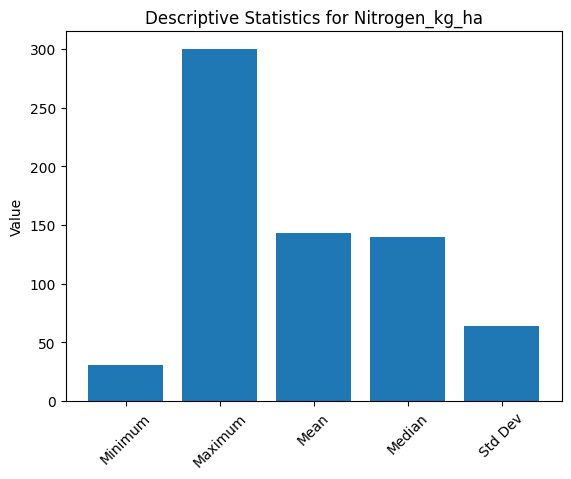

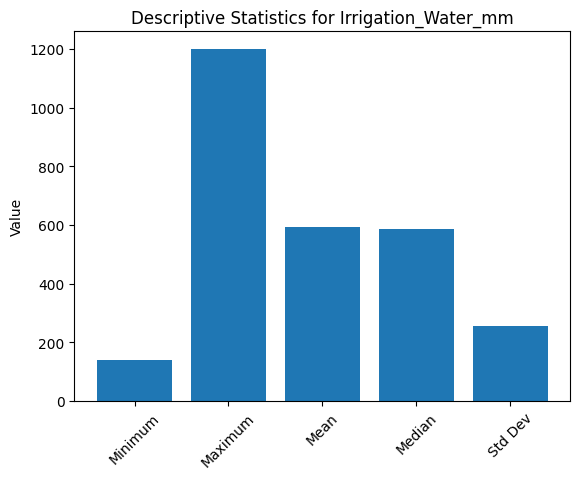

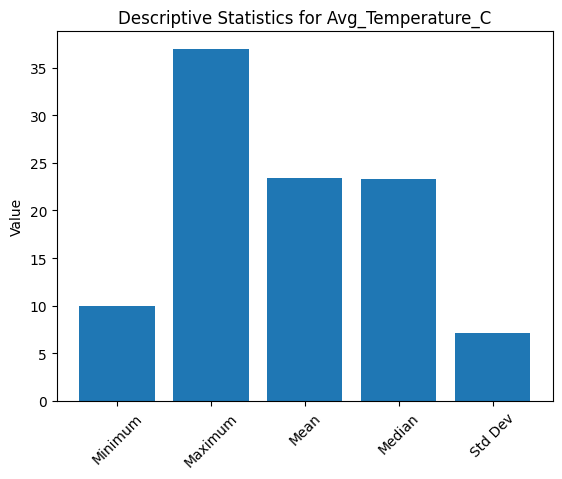

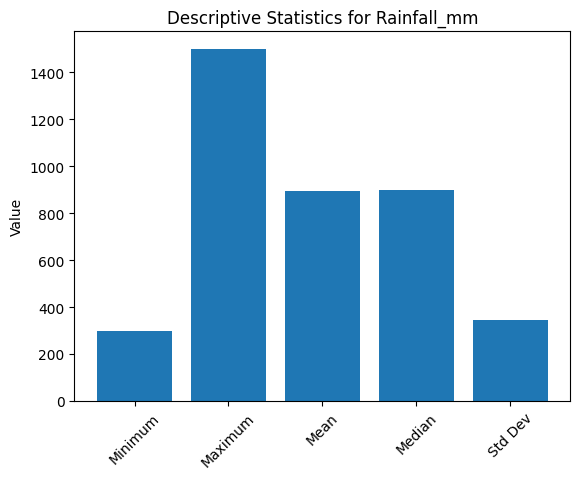

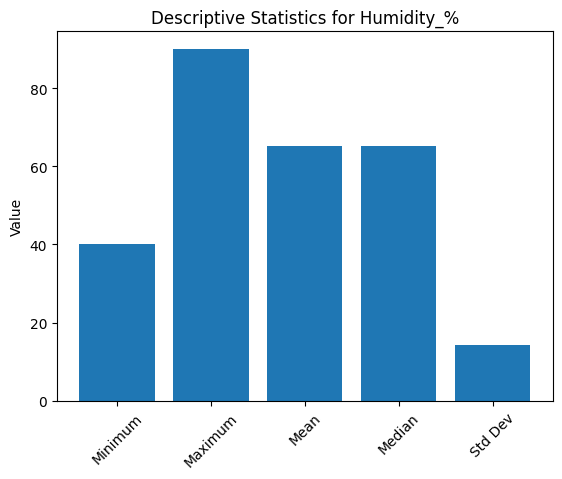

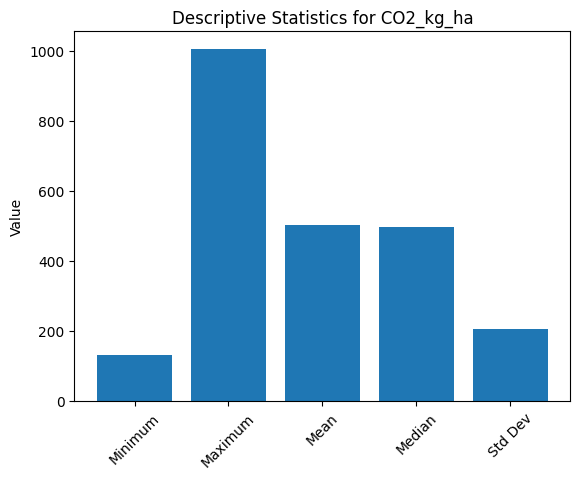

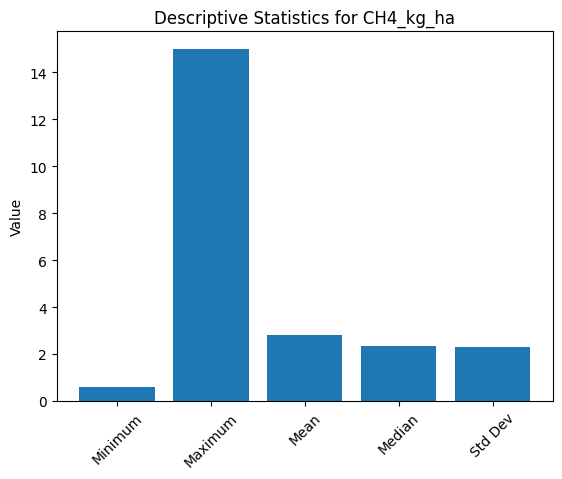

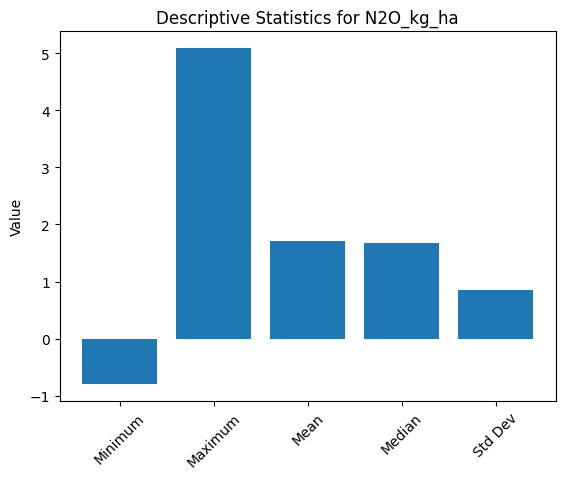

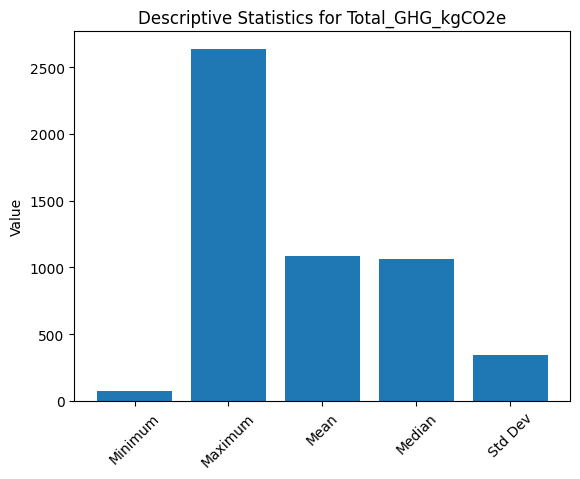

In [86]:
#1
numerical_df = df.select_dtypes(include=['int64', 'float64'])
descriptive_stats = numerical_df.describe()
print(descriptive_stats)

#Bar Graphs
for column in numerical_df.columns:


    stats = {
        "Minimum": numerical_df[column].min(),
        "Maximum": numerical_df[column].max(),
        "Mean": numerical_df[column].mean(),
        "Median": numerical_df[column].median(),
        "Std Dev": numerical_df[column].std()
    }

    plt.figure()
    plt.bar(stats.keys(), stats.values())
    plt.title(f"Descriptive Statistics for {column}")
    plt.ylabel("Value")
    plt.xticks(rotation=45)
    plt.show()

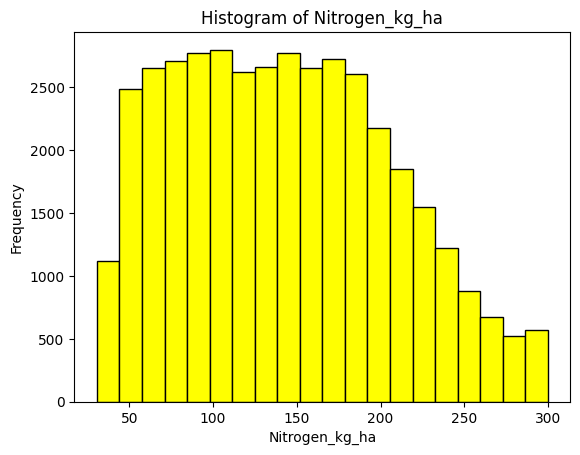

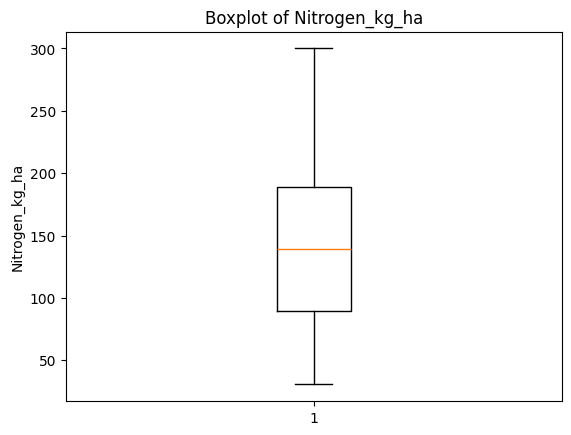

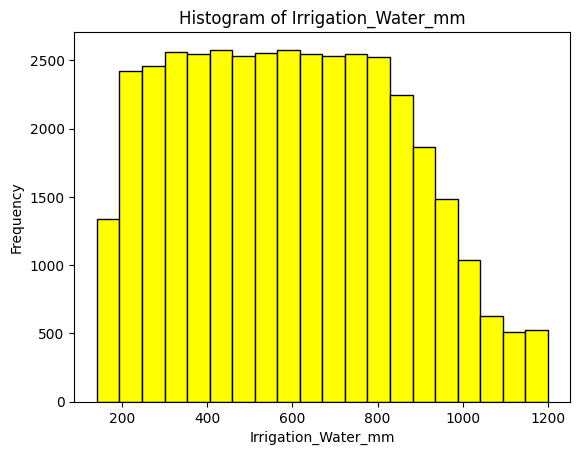

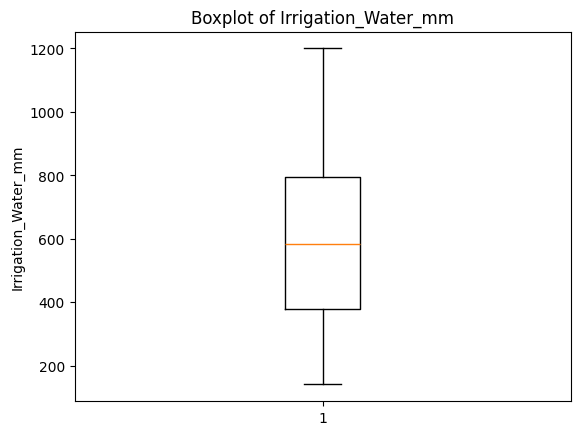

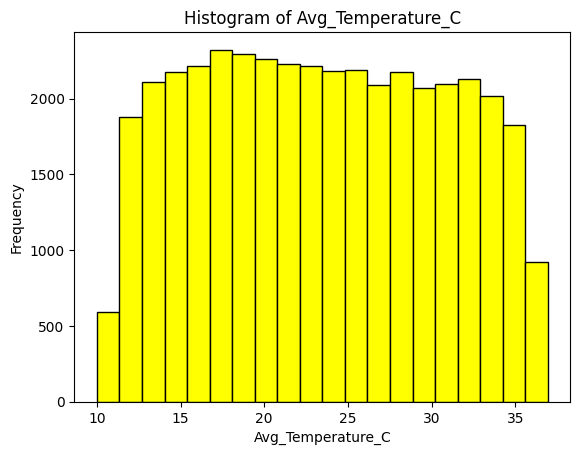

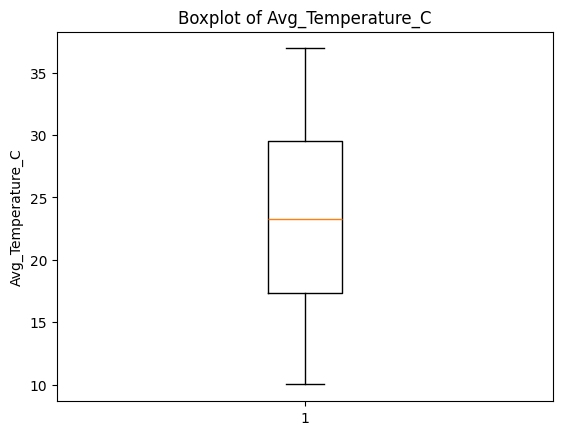

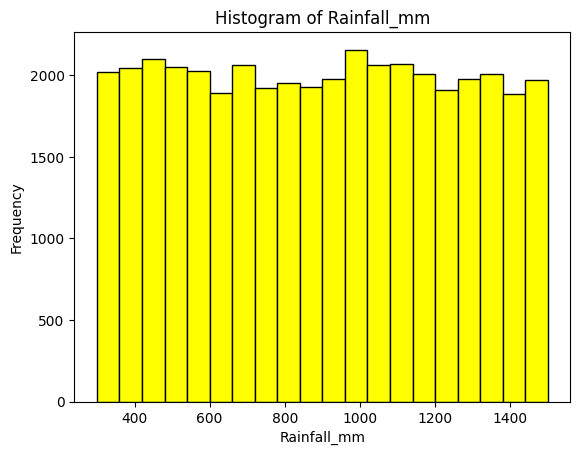

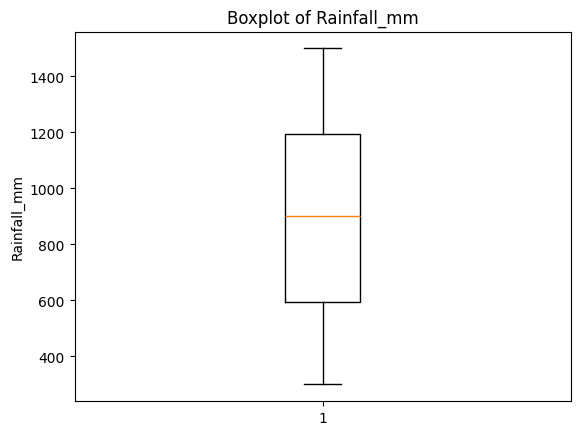

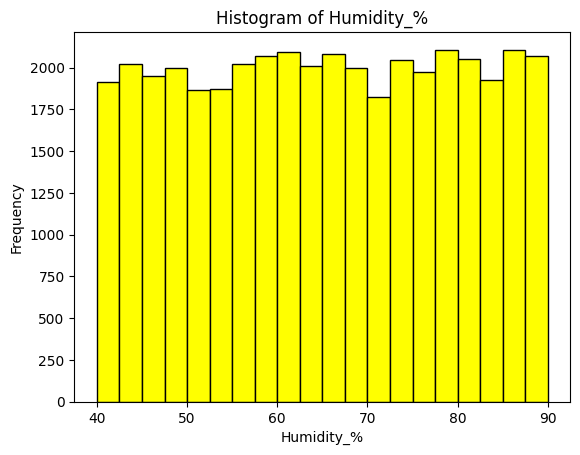

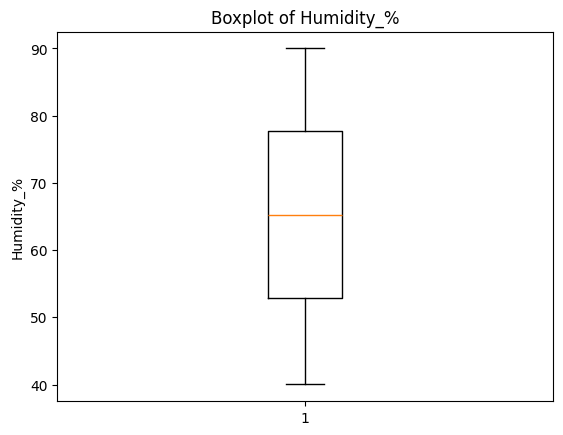

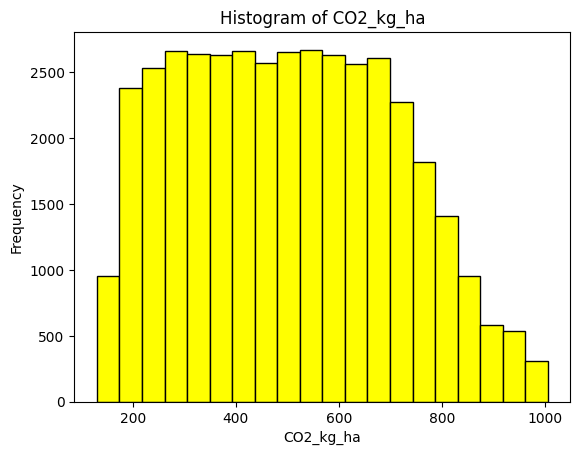

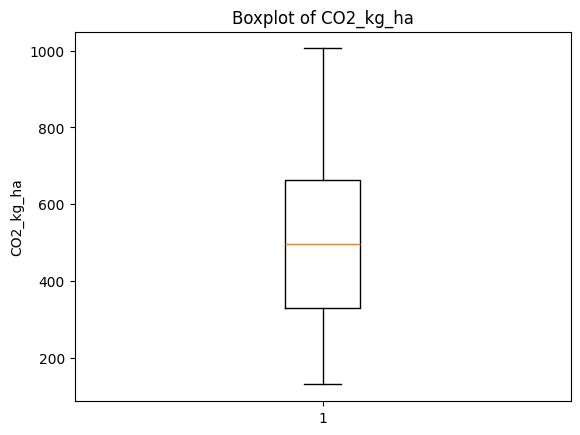

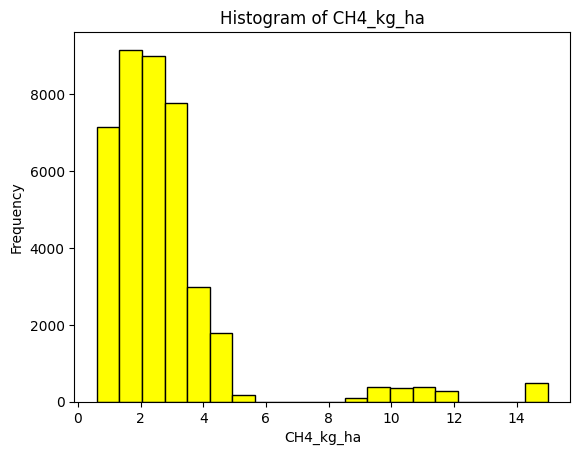

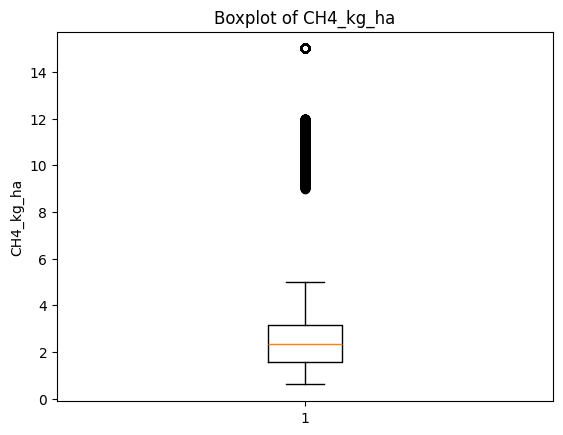

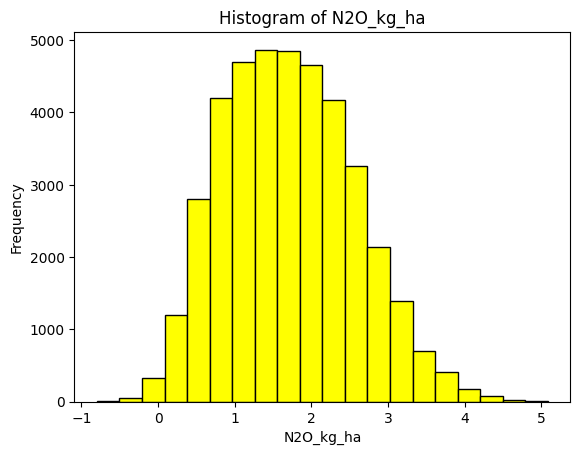

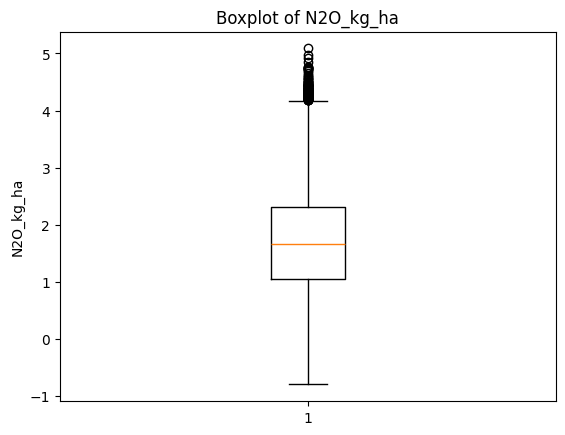

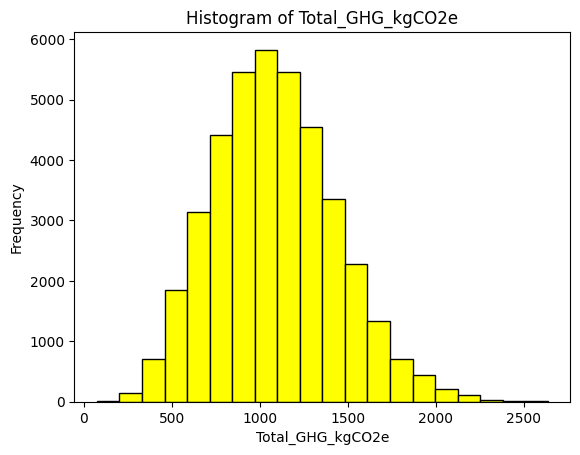

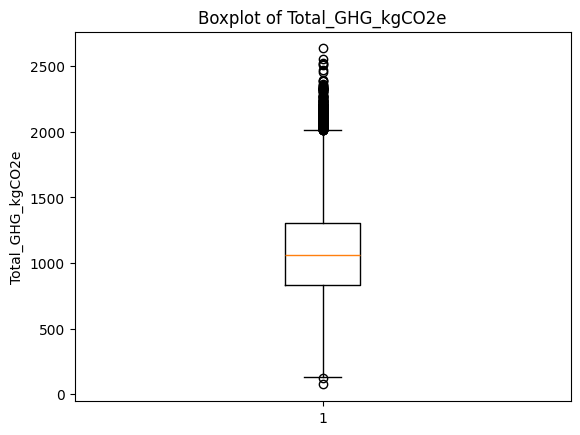

In [87]:
#2
    # histogram
for column in numerical_df.columns:
      plt.figure()
      plt.hist(numerical_df[column], bins=20,color='yellow',edgecolor='black')
      plt.title(f"Histogram of {column}")
      plt.xlabel(column)
      plt.ylabel("Frequency")
      plt.show()

          # boxplot
      plt.figure()
      plt.boxplot(numerical_df[column])
      plt.title(f"Boxplot of {column}")
      plt.ylabel(column)
      plt.show()

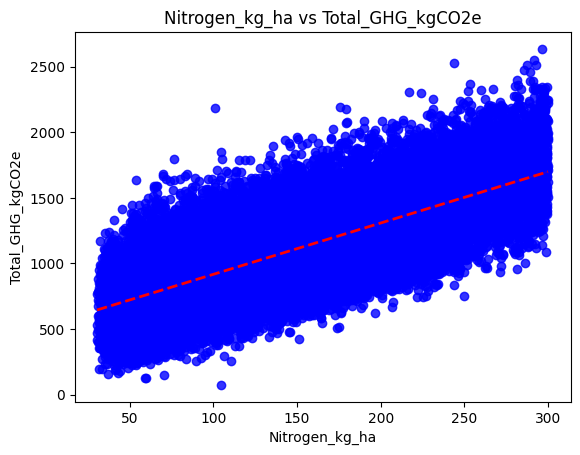

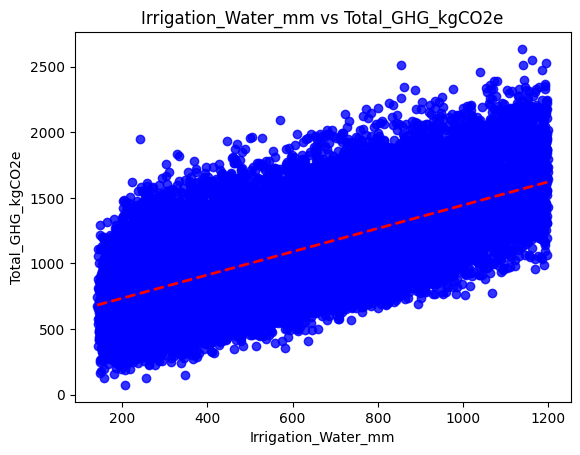

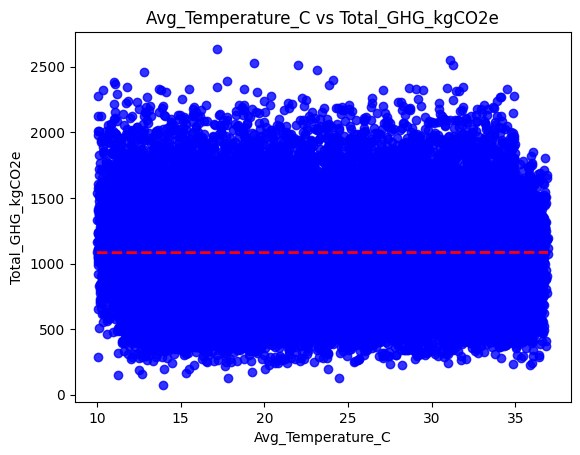

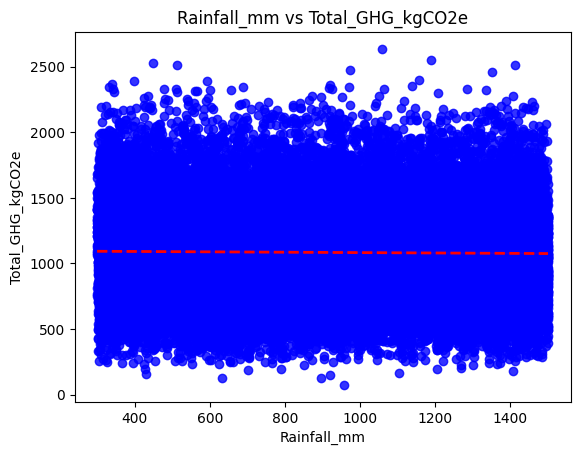

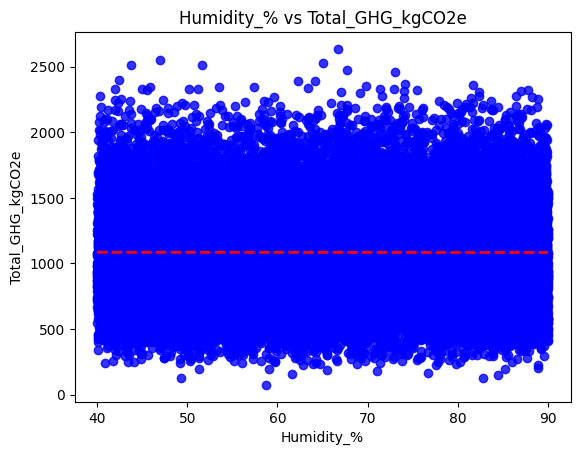

In [88]:
#3
target = "Total_GHG_kgCO2e"

input_features = [
    "Nitrogen_kg_ha",
    "Irrigation_Water_mm",
    "Avg_Temperature_C",
    "Rainfall_mm",
    "Humidity_%"
]


for feature in input_features:

    x = df[feature]
    y = df[target]

    plt.figure()
    # plt.scatter(x, y)
    sns.regplot(x=x, y=y, color='blue', line_kws={"color": "red", "lw": 2,"ls":'--'})


    plt.xlabel(feature)
    plt.ylabel(target)
    plt.title(f"{feature} vs {target}")

    plt.show()

**Analysis of Scatter Plots:**

Target Variable: Total_GHG_kgCO2e

Input Variables
1. Nitrogen_kg_ha: Positive relationship, dense plot, low outliers
2. Irrigation_Water_mm: Positive relationship, dense plot, low outliers
3. Avg_Temperature_C: Neutral, horizontal cloud shape, dense plot, low outliers
4. Rainfall_mm: Neutral, horizontal cloud shape, dense plot, low outliers
5. Humidity_%: Neutral, horizontal cloud shape, dense plot, relatively more outliers



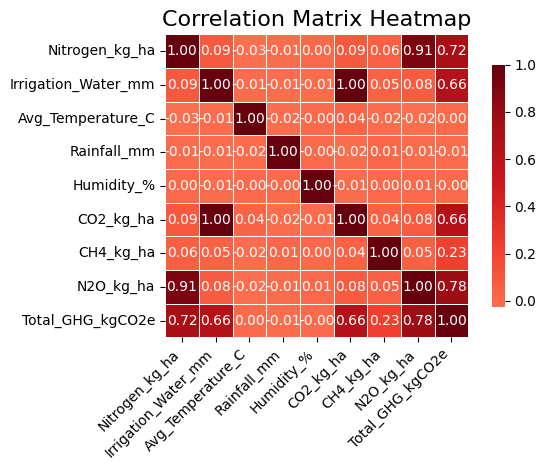

In [89]:
#4
corr_matrix = numerical_df.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    center=0,
    linewidths=0.5,
    linecolor='white',
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# **Additional Plots**

1. **Pairplot**

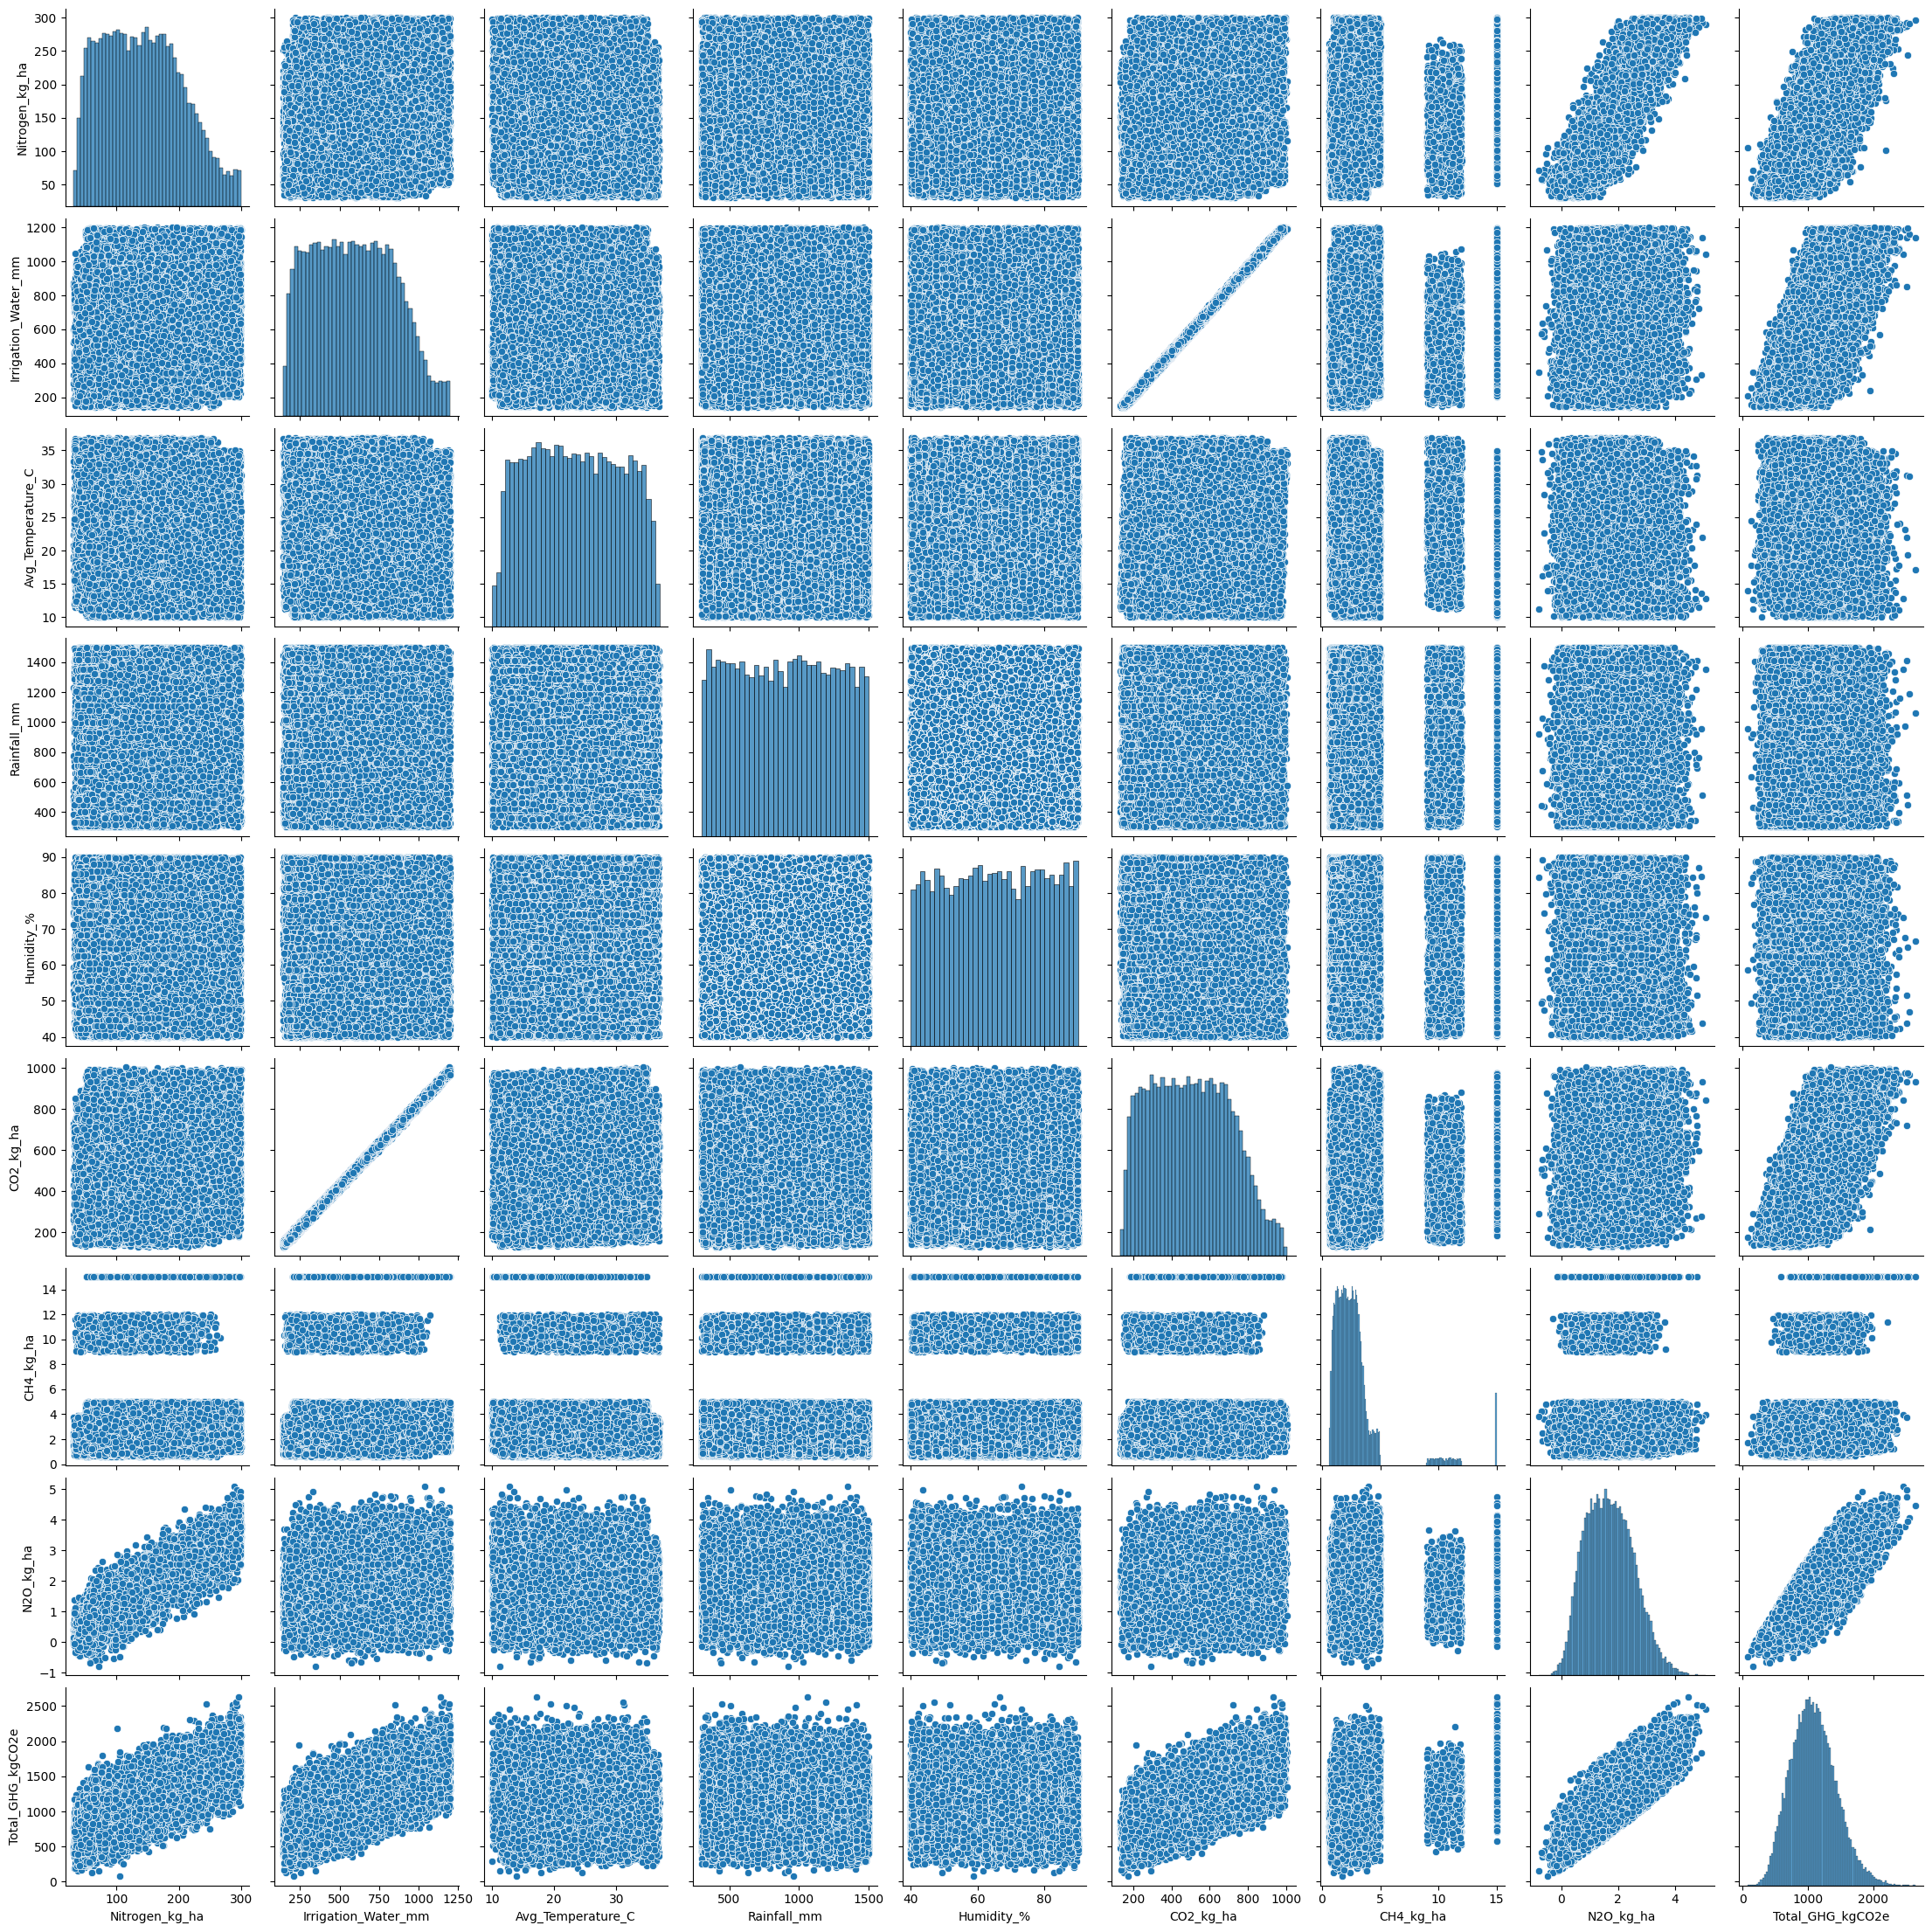

In [90]:
sns.pairplot(numerical_df)
plt.show()

2. **Violinplot**

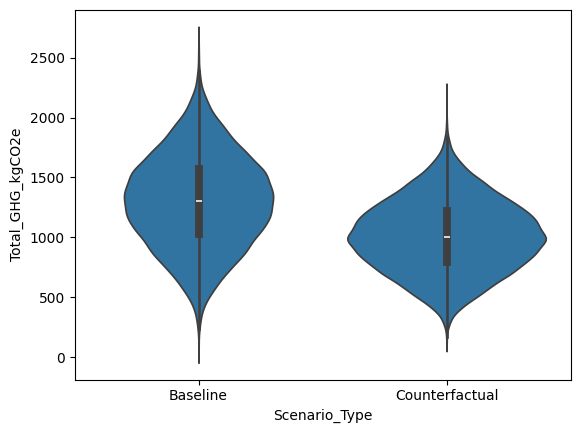

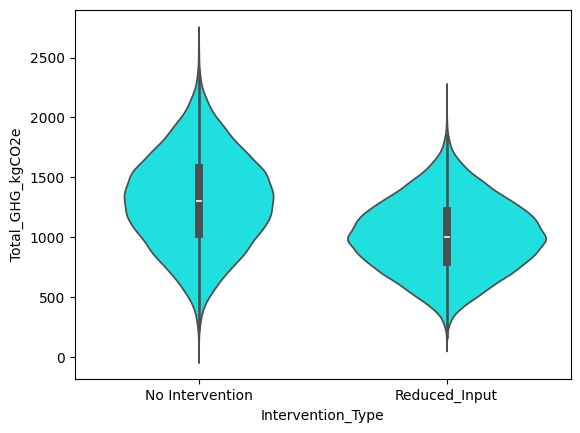

In [91]:

sns.violinplot(x="Scenario_Type", y="Total_GHG_kgCO2e", data=df)
plt.show()

sns.violinplot(x="Intervention_Type", y="Total_GHG_kgCO2e", data=df,color='cyan')
plt.show()

## **EDA Summary**

* Most input features (Nitrogen, Irrigation, Temperature, Rainfall, Humidity) show fairly balanced distributions with moderate spread and limited extreme outliers.

* Methane (CH₄) and Nitrous Oxide (N₂O) emissions display more high-end outliers, while total GHG emissions are slightly right-skewed with some high-emission extremes.

* Nitrogen and Irrigation show clear positive relationships with Total GHG emissions, meaning higher input use leads to higher emissions.

* Temperature, Rainfall, and Humidity show weak or negligible linear relationships with Total GHG emissions.

* Correlation analysis confirms:

  * Strong positive correlations between Total GHG and its components (CO₂, CH₄, N₂O).

  * Moderate positive correlations with Nitrogen and Irrigation.

  * Minimal correlation with weather variables.

  * Low inter-correlation among input features, suggesting limited multicollinearity.

* Scenario analysis (violin plots) indicates:

  * Baseline scenarios have higher and more variable emissions.

  * Counterfactual and intervention scenarios show lower, more stable emissions, suggesting interventions are effective in reducing and stabilizing GHG output.

# **Linear Regression**

1. Formulate emission prediction as a regression problem.
2. Implement Linear Regression using:
    * Batch Gradient Descent
    * Stochastic Gradient Descent
3. Split data into training and testing sets.
4. Evaluate models using MAE, MSE, and R².
5. Compare optimization behavior and results using metrics and plots.
6. Visualize the results


**Problem Definition**

Target variable ($y$) : Total_GHG_kgCO2e

Input features ($x_i$) : Nitrogen, Irrigation, Temperature, Rainfall, Humidity

Model relationship : predict continuous emission values

$y = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n + \epsilon$



In [92]:
#generating training and testing dataset
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

exclude_cols = ["CO2_kg_ha", "CH4_kg_ha", "N2O_kg_ha", target,"Emission_Class"]
#here emmission class is a data feature added in the end at classificatuion stage, so it has no relevance in provided

feature_cols = [col for col in numerical_cols if col not in exclude_cols]

print("Selected Features:", feature_cols)

X = df[feature_cols].values
y = df[target].values.reshape(-1,1)

np.random.seed(42)
indices = np.random.permutation(len(X))
train_size = int(0.8 * len(X))

train_idx = indices[:train_size]
test_idx = indices[train_size:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

Selected Features: ['Nitrogen_kg_ha', 'Irrigation_Water_mm', 'Avg_Temperature_C', 'Rainfall_mm', 'Humidity_%']


BGD Metrics
MAE: 92.8463059885974
MSE: 14663.787017142397
R2: 0.8776943770193499

SGD Metrics
MAE: 94.87317347474642
MSE: 15486.799934657773
R2: 0.8708299082787602

Last Cost of BGD: 7322.072376566764


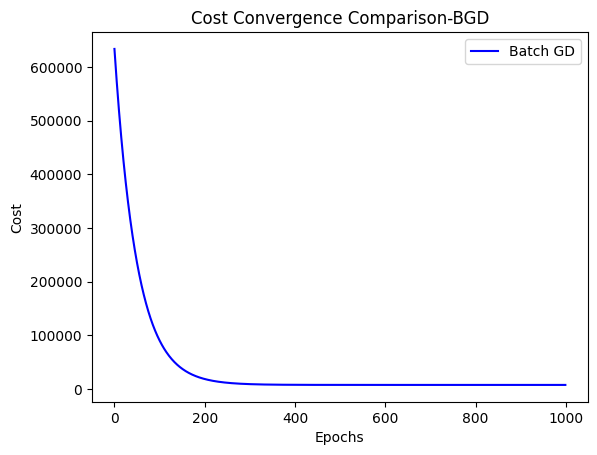


Last Cost of SGD: 7739.689160185363


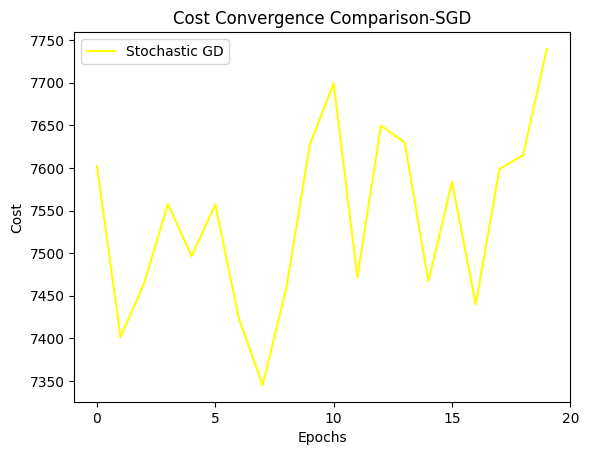

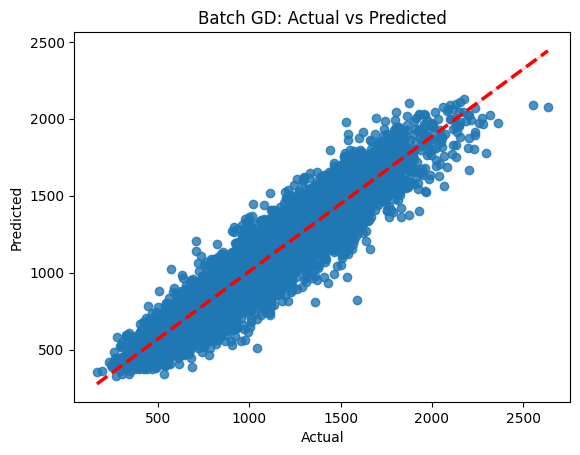

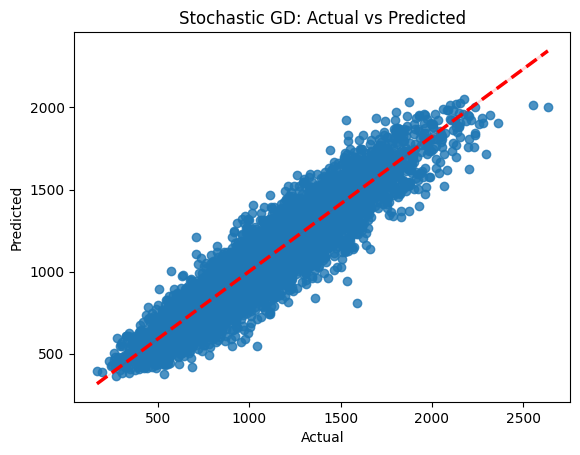


Coefficients:

Nitrogen_kg_ha: 231.77936591615565
Irrigation_Water_mm: 206.98345079494786
Avg_Temperature_C: 8.006203911774971
Rainfall_mm: -0.2058797784006158
Humidity_%: 0.8969661666226515


In [93]:

# bias addition
def linear_bias(X):
    X = np.c_[np.ones(X.shape[0]), X]
    return X

# cost of both reg
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X @ theta
    return (1/(2*m)) * np.sum((predictions - y)**2)


# bgd func
def batch_gradient_descent(X, y, lr=0.01, epochs=1000):
    m, n = X.shape
    theta = np.zeros((n,1))
    costs = []

    for _ in range(epochs):
        predictions = X @ theta
        gradient = (1/m) * (X.T @ (predictions - y))
        theta -= lr * gradient
        costs.append(compute_cost(X, y, theta))

    return theta, costs

X_train_lin = linear_bias(X_train)
X_test_lin = linear_bias(X_test)

def stochastic_gradient_descent(X, y, lr=0.01, epochs=20):
    m, n = X.shape
    theta = np.zeros((n,1))
    costs = []

    for _ in range(epochs):

        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(m):
            xi = X_shuffled[i].reshape(1,-1)
            yi = y_shuffled[i].reshape(1,-1)

            prediction = xi @ theta
            gradient = xi.T @ (prediction - yi)

            theta -= lr * gradient

        costs.append(compute_cost(X, y, theta))
    return theta, costs




# train
theta_bgd, cost_bgd = batch_gradient_descent(X_train_lin, y_train)
theta_sgd, cost_sgd = stochastic_gradient_descent(X_train_lin, y_train)


# predicted
y_pred_bgd = X_test_lin @ theta_bgd
y_pred_sgd = X_test_lin @ theta_sgd


# evaluation: comparision between predicted and actual
def MAE(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def MSE(y, y_pred):
    return np.mean((y - y_pred)**2)

def R2(y, y_pred):
    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - (ss_res/ss_tot)

print("BGD Metrics")
print("MAE:", MAE(y_test, y_pred_bgd))
print("MSE:", MSE(y_test, y_pred_bgd))
print("R2:", R2(y_test, y_pred_bgd))

print("\nSGD Metrics")
print("MAE:", MAE(y_test, y_pred_sgd))
print("MSE:", MSE(y_test, y_pred_sgd))
print("R2:", R2(y_test, y_pred_sgd))

last_bgd_cost=cost_bgd[-1]
last_sgd_cost=cost_sgd[-1]

# optimization plot
print("\nLast Cost of BGD:", last_bgd_cost)
plt.figure()
plt.plot(cost_bgd, label="Batch GD",color="blue")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.title("Cost Convergence Comparison-BGD")
plt.legend()
plt.show()

print("\nLast Cost of SGD:", last_sgd_cost)
plt.figure()
plt.plot(cost_sgd, label="Stochastic GD",color="yellow")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.xticks(range(0, len(cost_sgd)+1, 5))
plt.title("Cost Convergence Comparison-SGD")
plt.legend()
plt.show()


# prediction plots
plt.figure()
sns.regplot(
    x=y_test,
    y=y_pred_bgd,
    line_kws={'color': 'red', 'linewidth': 2.5, 'ls':'--'}
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Batch GD: Actual vs Predicted")
plt.show()

plt.figure()
sns.regplot(
    x=y_test,
    y=y_pred_sgd,
    line_kws={'color': 'red', 'linewidth': 2.5, 'ls':'--'}
)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Stochastic GD: Actual vs Predicted")
plt.show()

metrics = ["MAE", "MSE", "R2"]
bgd_values = [MAE(y_test, y_pred_bgd), MSE(y_test, y_pred_bgd), R2(y_test, y_pred_bgd)]
sgd_values = [MAE(y_test, y_pred_sgd), MSE(y_test, y_pred_sgd), R2(y_test, y_pred_sgd)]

coeff=[]
for i in range(len(feature_cols)):
  coeff.append(theta_bgd[i+1][0])

print("\nCoefficients:\n")
for i in range(len(feature_cols)):
  print(f"{feature_cols[i]}: {coeff[i]}")




Most significant features are Nitrogen_kg_ha, Irrigation_Water_mm

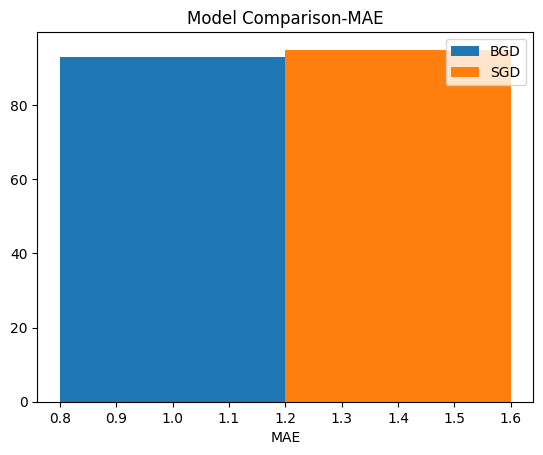

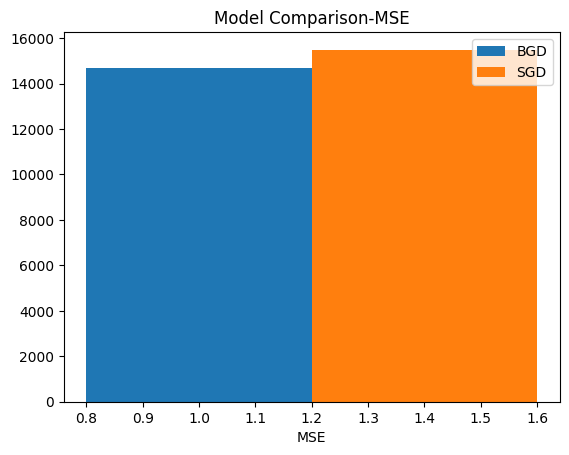

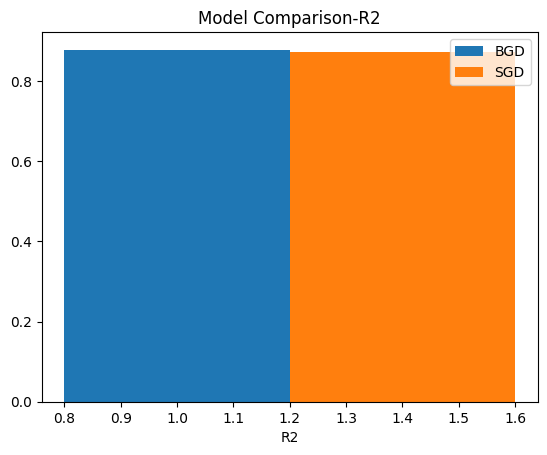

In [94]:
#bar graphs
basex = [1];
for j in range(len(metrics)):
  plt.figure()
  plt.bar(basex, bgd_values[j], width=0.4, label="BGD")
  plt.bar([i + 0.4 for i in basex], sgd_values[j], width=0.4, label="SGD")
  plt.xlabel(metrics[j])
  plt.legend()
  plt.title(f"Model Comparison-{metrics[j]}")
  plt.show()

**Comparision**

* Both the models have about 93 units of MAE(BGD has a slight edge over SGD), meaning they are off by about 93 units of Total_GHG in prediction.
* BGD has slightly lower MSE, meaning it exhibits fewer large mistakes.
* Both the models explain about 88% of the variation in Total_GHG, which is considered strong performance.
* BGD and SGD show nearly identical outcomes, with the only major difference in cost trend relative to number of runthroughs(*epochs*) of the dataset.
* BGD converges smoothly and steadily, while SGD converges faster but would typically exhibit noisier updates.
* Both appear to converge to similar low cost, this means both methods successfully minimized MSE.
* BGD and SGD both have large number of difference in epochs but converged to similar results due to difference in weight updation process: BGD updates once per epoch and SGD updates multiple times per epoch sample.

Input Variables with largest impact: Nitrogen_kg_ha, Irrigation_Water_mm according to heatmap and coefficient comparision.

# **Polynomial Regression and Regularization**
1. Apply polynomial features of degree two.
2. Train polynomial regression models with:
    * L1 regularization
    * L2 regularization
3. Evaluate and compare results with linear regression.
4. Summarize the performance differences and the effects of model complexity.
5. Visualize the results

Target variable ($y$) : Total_GHG_kgCO2e

Input features ($x_i$) : Nitrogen, Irrigation, Temperature, Rainfall, Humidity

Model relationship : predict continuous emission values

Mathematically: $ \hat{y} = w_0 + w_1 x + w_2 x^2 $

## L1 Regularization (Lasso Regression)

Cost function with L1 penalty:
$J_{L1}(\mathbf{w}) =\frac{1}{2n} \sum_{i=1}^{n}\left( y_i - \mathbf{w}^T \boldsymbol{\phi}(x_i) \right)^2+ \lambda \sum_{j=1}^{d} |w_j|$


## L2 Regularization (Ridge Regression)

Cost function with L2 penalty:
$J_{L2}(\mathbf{w}) =\frac{1}{2n} \sum_{i=1}^{n}\left( y_i - \mathbf{w}^T \boldsymbol{\phi}(x_i) \right)^2+ \lambda \sum_{j=1}^{d} w_j^2$



In [95]:
def polynomial_features(X):
    n_samples,n_features = X.shape
    poly =[np.ones(n_samples)]  # bias

    # original features
    for i in range(n_features):
        poly.append(X[:, i])

    # squared terms
    for i in range(n_features):
        poly.append(X[:, i] ** 2)

    # interaction terms
    for i in range(n_features):
        for j in range(i+1, n_features):
            poly.append(X[:, i] * X[:, j])

    return np.column_stack(poly)

X_train_poly = polynomial_features(X_train)
X_test_poly = polynomial_features(X_test)

print("Polynomial feature shape:", X_train_poly.shape)

def ridge_regression(X, y, lr=0.01, epochs=1500, lam=0.1):
    m, n = X.shape
    theta = np.zeros((n,1))
    costs = []

    for _ in range(epochs):
        reg = (lam/m)*theta
        reg[0] = 0
        gradient = (1/m)*(X.T @ (X @ theta - y)) + reg
        theta -= lr * gradient
        costs.append(compute_cost(X, y, theta))

    return theta, costs

theta_ridge, cost_ridge = ridge_regression(X_train_poly, y_train, lam=0.5)

def lasso_regression(X, y, lr=0.01, epochs=1500, lam=0.1):
    m, n = X.shape
    theta = np.zeros((n,1))
    costs = []

    for _ in range(epochs):
        reg = (lam/m)*np.sign(theta)
        reg[0] = 0
        gradient = (1/m)*(X.T @ (X @ theta - y)) + reg
        theta -= lr * gradient
        costs.append(compute_cost(X, y, theta))

    return theta, costs

theta_lasso, cost_lasso = lasso_regression(X_train_poly, y_train, lam=0.5)

def MAE(y, y_pred):
    return np.mean(np.abs(y - y_pred))

def MSE(y, y_pred):
    return np.mean((y - y_pred)**2)

def R2(y, y_pred):
    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - (ss_res/ss_tot)


models = {
    "Ridge": theta_ridge,
    "Lasso": theta_lasso
}

for name, theta in models.items():
    y_pred = X_test_poly @ theta
    print(f"\n{name} Regression")
    print("MAE:", MAE(y_test, y_pred))
    print("MSE:", MSE(y_test, y_pred))
    print("R2:", R2(y_test, y_pred))



Polynomial feature shape: (32000, 21)

Ridge Regression
MAE: 99.79958410699648
MSE: 16765.262486025862
R2: 0.8601666902014851

Lasso Regression
MAE: 99.79976662383915
MSE: 16765.32227218663
R2: 0.8601661915456037


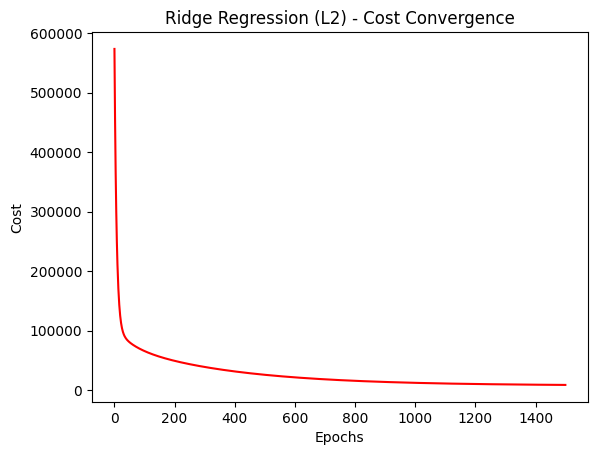

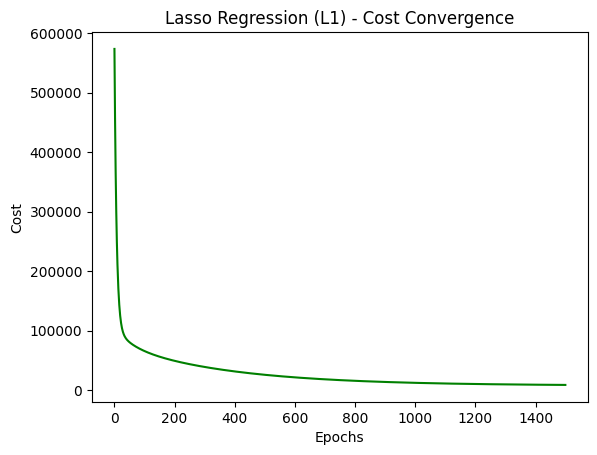

In [96]:

plt.figure()
plt.plot(cost_ridge, color='red')
plt.title("Ridge Regression (L2) - Cost Convergence")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

plt.figure()
plt.plot(cost_lasso, color='green')
plt.title("Lasso Regression (L1) - Cost Convergence")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.show()

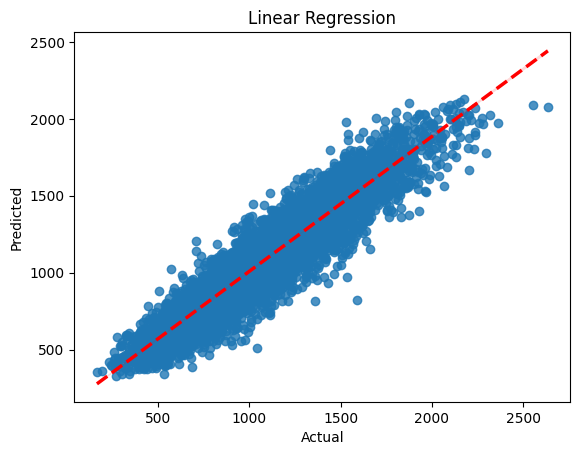

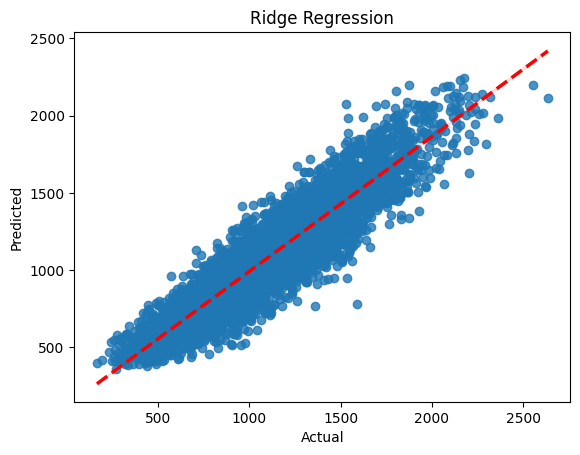

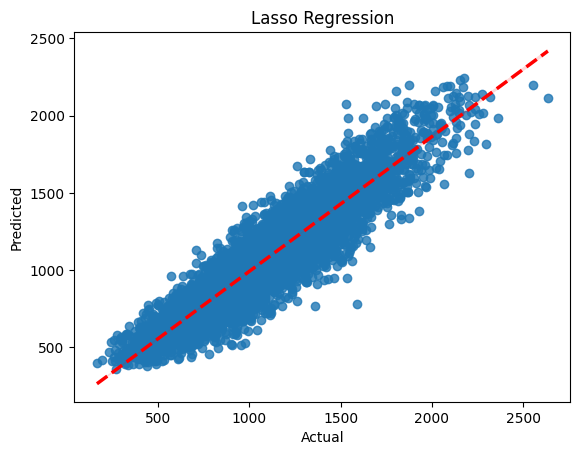

In [97]:
plt.figure()
sns.regplot(
    x=y_test,
    y=X_test_lin @ theta_bgd,
    line_kws={'color': 'red', 'linewidth': 2.5, 'ls':'--'}
)
plt.title("Linear Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

plt.figure()
sns.regplot(
    x=y_test,
    y=X_test_poly @ theta_ridge,
    line_kws={'color': 'red', 'linewidth': 2.5, 'ls':'--'}
)
plt.title("Ridge Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

plt.figure()
sns.regplot(
    x=y_test,
    y=X_test_poly @ theta_lasso,
    line_kws={'color': 'red', 'linewidth': 2.5, 'ls':'--'}
)
plt.title("Lasso Regression")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

**Comparison**
* The MSE error for both Polynomial regressions in general is more as compared
to Linear Regression because the model overfits. As the degree of equation increases the fitting increases.

* Higher λ (regularization strength) increases penalty which reduces overfitting and increases bias.

* Whether we use L1 or L2 regularization, it doesn't affect the model R2 value because the number of features are limited, less multicollinearity and dataset size is small compared to conventional ones.

* It can also be inferred features are relatively more linearly related to target variable than a polynomial curve(true relationship is mostly linear) that's why polynomial regression error is more.

* For both L1 and L2 regression the cost of convergence is very close due to small features and similar regularization.





# **Classification Reformulation**
1. Convert the regression task into a classification problem by defining a clear, well-justified labeling strategy (e.g., low/medium/high emissions).
2. Apply a linear classifier:
    * Logistic Regression
    * Naive Bayes
    * Perceptron
3. Present results and discuss the suitability and limitations of the classification approach.
4. Visualize the results

**Problem Definition**

Target variable ($y$) : y ∈ {0,1,2}

Input features ($x_i$) : Nitrogen, Irrigation, Temperature, Rainfall, Humidity

Model relationship : Instead of predicting a continuous value, we predict a class label.

Mathematically:

$\hat{y} = \arg\max_{k} P(y = k \mid x)$


Where:

* $\hat{y}$= Predicted class label (model's output)
* $\arg\max_{k}$= “Argument of the maximum” thus selects the value of
$k$
 that maximizes the expression
* $k$=Class index
* $P(y = k \mid x)$ = Posterior probability that the output belongs to class
$k$
, given input features
$x$
* $y$ = Actual class label
* $x$ = Input features

In [98]:
q1 = df["Total_GHG_kgCO2e"].quantile(0.33)
q2 = df["Total_GHG_kgCO2e"].quantile(0.66)

def classify_emission(x):
    if x <= q1:
        return 0   # low
    elif x <= q2:
        return 1   # medium
    else:
        return 2   # high


df["Emission_Class"] = df["Total_GHG_kgCO2e"].apply(classify_emission)

df["Emission_Class"].value_counts()

y = df["Emission_Class"].values

y = df["Emission_Class"].values
y_train_ec, y_test_ec = y[train_idx], y[test_idx]



In [99]:

class LogisticRegressionScratch:
    def __init__(self, lr=0.01, epochs=50):
        self.lr = lr
        self.epochs = epochs

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.weights = {}
        self.bias = {}

        for c in self.classes:
            y_binary = (y == c).astype(int)
            w = np.zeros(X.shape[1])
            b = 0

            for _ in range(self.epochs):
                linear = np.dot(X, w) + b
                y_pred = self.sigmoid(linear)

                dw = np.dot(X.T, (y_pred - y_binary)) / len(y)
                db = np.sum(y_pred - y_binary) / len(y)

                w -= self.lr * dw
                b -= self.lr * db

            self.weights[c] = w
            self.bias[c] = b

    def predict(self, X):
        scores = []
        for c in self.classes:
            linear = np.dot(X, self.weights[c]) + self.bias[c]
            scores.append(self.sigmoid(linear))
        scores = np.array(scores)
        return np.argmax(scores, axis=0)

In [100]:
log_model = LogisticRegressionScratch()
log_model.fit(X_train, y_train_ec)

y_pred_log = log_model.predict(X_test)

In [101]:
class GaussianNBScratch:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.mean = {}
        self.var = {}
        self.prior = {}

        for c in self.classes:
            X_c = X[y == c]
            self.mean[c] = X_c.mean(axis=0)
            self.var[c] = X_c.var(axis=0)
            self.prior[c] = X_c.shape[0] / X.shape[0]

    def gaussian(self, x, mean, var):
        return np.exp(-(x - mean)**2 / (2 * var + 1e-9)) / np.sqrt(2 * np.pi * var + 1e-9)

    def predict(self, X):
        predictions = []
        for x in X:
            posteriors = []
            for c in self.classes:
                prior = np.log(self.prior[c])
                likelihood = np.sum(np.log(self.gaussian(x, self.mean[c], self.var[c])))
                posteriors.append(prior + likelihood)
            predictions.append(self.classes[np.argmax(posteriors)])
        return np.array(predictions)

In [102]:
nb_model = GaussianNBScratch()
nb_model.fit(X_train, y_train_ec.flatten())
y_pred_nb = nb_model.predict(X_test)

In [103]:
class PerceptronScratch:
    def __init__(self, lr=0.01, epochs=50):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        self.classes = np.unique(y)
        self.weights = {}
        self.bias = {}

        for c in self.classes:
            y_binary = (y == c).astype(int)
            w = np.zeros(X.shape[1])
            b = 0

            for _ in range(self.epochs):
                for i in range(len(X)):
                    linear = np.dot(X[i], w) + b
                    pred = 1 if linear >= 0 else 0
                    update = self.lr * (y_binary[i] - pred)
                    w += update * X[i]
                    b += update

            self.weights[c] = w
            self.bias[c] = b

    def predict(self, X):
        scores = []
        for c in self.classes:
            linear = np.dot(X, self.weights[c]) + self.bias[c]
            scores.append(linear)
        scores = np.array(scores)
        return np.argmax(scores, axis=0)

In [104]:
perc_model = PerceptronScratch()
perc_model.fit(X_train, y_train_ec)
y_pred_perc = perc_model.predict(X_test)

In [105]:
def evaluate_model(name, y_true, y_pred):
    accuracy = np.mean(y_true == y_pred)

    print(f"\n{name}")
    print("Accuracy:", accuracy)

    classes = np.unique(y_true)
    for c in classes:
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp + 1e-9)
        recall = tp / (tp + fn + 1e-9)
        f1 = 2 * precision * recall / (precision + recall + 1e-9)

        print(f"Class {c} Precision: {precision:.3f}, Recall: {recall:.3f}, F1: {f1:.3f}")

evaluate_model("Logistic Regression", y_test_ec, y_pred_log)
evaluate_model("Naive Bayes", y_test_ec, y_pred_nb)
evaluate_model("Perceptron", y_test_ec, y_pred_perc)




Logistic Regression
Accuracy: 0.66475
Class 0 Precision: 0.636, Recall: 0.983, F1: 0.772
Class 1 Precision: 0.691, Recall: 0.026, F1: 0.049
Class 2 Precision: 0.694, Recall: 0.969, F1: 0.809

Naive Bayes
Accuracy: 0.794
Class 0 Precision: 0.858, Recall: 0.809, F1: 0.833
Class 1 Precision: 0.661, Recall: 0.764, F1: 0.709
Class 2 Precision: 0.892, Recall: 0.808, F1: 0.848

Perceptron
Accuracy: 0.6725
Class 0 Precision: 0.679, Recall: 0.893, F1: 0.771
Class 1 Precision: 0.543, Recall: 0.272, F1: 0.362
Class 2 Precision: 0.718, Recall: 0.844, F1: 0.776


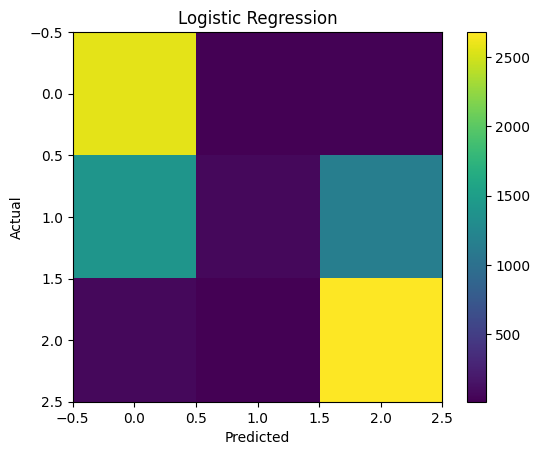

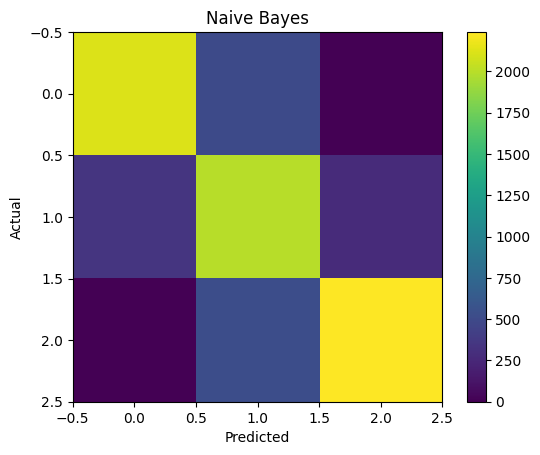

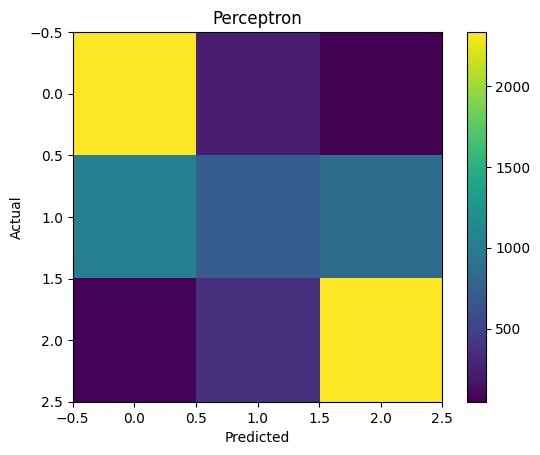

In [106]:
def plot_confusion_matrix(y_true, y_pred, title):
    classes = np.unique(y_true)
    matrix = np.zeros((len(classes), len(classes)))

    for i in classes:
        for j in classes:
            matrix[i,j] = np.sum((y_true == i) & (y_pred == j))

    plt.figure()
    plt.imshow(matrix)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.colorbar()
    plt.show()

plot_confusion_matrix(y_test_ec, y_pred_log, "Logistic Regression")
plot_confusion_matrix(y_test_ec, y_pred_nb, "Naive Bayes")
plot_confusion_matrix(y_test_ec, y_pred_perc, "Perceptron")

# **Comparison**
 **Logistic Regression**

$P(y = 1 \mid x) = \frac{1}{1 + e^{-(w^T x + b)}}$

The confusion matrix shows strong diagonal dominance, indicating effective classification performance. The model accurately distinguishes low and high emission categories, while the medium emission class exhibits higher misclassification due to overlap between neighbouring categories. This behavior agrees with theoretical expectations of linear classifiers applied to discretized continuous targets.

 **Naive Bayes**

$P(x \mid y) = \prod_{i=1}^{n} P(x_i \mid y)$

The Naive Bayes confusion matrix shows strong diagonal dominance, indicating effective classification performance. The model accurately identifies low and high emission classes, while moderate misclassification occurs in the medium emission class due to overlap in feature distributions and the conditional independence assumption. Overall, the classifier performs reliably but may be slightly affected by correlated environmental variables.


 **Perceptron**

$
\hat{y} = \arg\max_{k} \left( w_k^T x + b_k \right)
$


The Perceptron confusion matrix shows strong performance for extreme emission categories, while moderate misclassification occurs for the medium emission class due to overlapping feature distributions. As a linear classifier without probabilistic modeling, the Perceptron is more sensitive to boundary ambiguity, resulting in slightly reduced classification stability.

 **Results**
The classification models showed varying performance across the three emission categories (Low, Medium, High). Among the models, Naive Bayes achieved the highest overall accuracy (79.4%) and demonstrated balanced precision, recall, and F1-scores across all classes. Logistic Regression and Perceptron performed well for the extreme classes (Low and High emissions) but struggled significantly with the Medium emission class, particularly Logistic Regression, which showed very low recall for that category. This is due to difficulty in separating the intermediate emission range using linear decision boundaries.

 **Strengths**

* Clear interpretability - Categorizing emissions into Low, Medium, and High makes the results easier to understand.

* Effective detection of extreme classes - All models performed well in identifying clearly low and high emission cases.

* Computational efficiency - Linear classifiers are simple, fast, and easy to implement from scratch.

 **Limitations**

* Information loss from discretization - The original emission variable was continuous, but converting it into discrete categories removes fine-grained differences between farms. Two farms with different emission values may fall into the same class, reducing precision.

* Boundary sensitivity - Samples near class thresholds may be misclassified despite having similar emission values.

* Reduced granularity - Unlike regression, classification does not provide exact emission estimates.

 **Suitability for Decision Making**

The classification approach is a well-suited approach for categorical decision-making scenarios such as medical diagnosis, spam detection, or image classifiaction. However, for applications requiring precise emission prediction or quantitative environmental assessment, regression models are more appropriate because they preserve continuous information.

 **More on information loss from discretization**

Discretization helps simplify interpretation but sacrifices precision. It transforms a continuous signal into coarse categorical bins, introducing artificial boundaries, reducing variance information, and possibly degrading model sensitivity, especially for intermediate classes.

# **Summary**
* Dataset is conventionally small but data is densely populated with relatively less number of  severe outliers exhibiting true relatioship closer to linear(easily approximated).
* BGD nominally better than SGD but mostly converged to same metrics and cost. The rate of change in cost was the only major difference due to differeing weight updation methodologies of both, we can say that the model is easy to optimize and has a single global minimum, with no extreme featue weighing problem.
* Polynomial regression fared a bit worse than linear models indicating the true dataset behaviour leaning towards linearizability, also due to possible overfitting which generally includes testing error that reduces predictability. Both L1 and L2 fared similar due to limited features, less multicollinearity and the size of the dataset. Correlation analysis confirmed moderate relationships with low multicollinearity, validating the feature selection strategy.
*  When reformulated as a classification problem (Low/Medium/High emissions), Naive Bayes achieved the highest accuracy (79.4%), while Logistic Regression and Perceptron struggled with the medium class due to overlapping feature distributions. Although classification improved interpretability for categorical decisions, it introduced information loss compared to regression.
* Compared to the earlier linear and polynomial regression models (which achieved high $R^2$ approx 0.86-0.88), the classification models show comparatively weaker and more variable performance, especially Logistic Regression. While regression tasks were well-fitted and stable, classification particularly for Class 1 (medium 66th percentile) reveals separation or imbalance issues.

* Overall, the dataset appears easier for continuous prediction than for discrete multi-class classification, which is expected as the target variable is continous and not discretely clustered in ranges.